# Beyond the Chains
## 04 — Historical NFL Team-Season Offensive Performance (2000–2025)

### Research Objective

Investigate and compare the rushing and passing performance of individual NFL teams across 26 regular seasons.

### Research Questions

1. Which NFL teams recorded the highest and lowest average rushing and passing yards per game?
2. How did individual teams' offensive production change over time?
3. Which teams exhibited the greatest consistency in rushing and passing production?
4. Which teams demonstrated strong performance in both rushing and passing?
5. How do individual team performances compare with league-wide averages?

### Statistical Methods

- Grouped descriptive statistics
- Measures of central tendency and dispersion
- Historical trend analysis
- Team rankings and percentiles
- Comparative data visualization
- Exploratory correlation analysis

### Observational Unit

The source data contains one observation per team per game.

Aggregating by season and team creates a team-season dataset, where each observation summarizes a team's performance across its regular-season games.



First we will start with 2025 to get a brief look at how it looks

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

print(sys.executable)

from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "exploratory_analysis":
    ROOT = ROOT.parent.parent
elif ROOT.name == "notebooks":
    ROOT = ROOT.parent

team_stats = pd.read_parquet(
    ROOT / "data" / "processed" / "team_stats_2000_2025.parquet"
)

# Regular-season observations only
offense = team_stats.loc[
    team_stats["season_type"] == "REG",
    [
        "season",
        "week",
        "game_id",
        "team",
        "opponent_team",
        "rushing_yards",
        "passing_yards"
    ]
].copy()

print("Team-game observations:", len(offense))
display(offense.head())


/Users/edwardhutchens/Documents/beyond-the-chains-analytics/.venv/bin/python
Team-game observations: 13418


,season,week,game_id,team,opponent_team,rushing_yards,passing_yards
0,2000,1,2000_01_ARI_NYG,ARI,NYG,43,318
1,2000,1,2000_01_SF_ATL,ATL,SF,95,264
2,2000,1,2000_01_BAL_PIT,BAL,PIT,140,199
3,2000,1,2000_01_TEN_BUF,BUF,TEN,129,174
4,2000,1,2000_01_CAR_WAS,CAR,WAS,112,183


In [6]:
# constructing our team-season data 

team_stats.groupby(["season", "team"])



#calculating each team's rushign and passing peformances across its games

team_season = (
    offense.groupby(["season", "team"])
    .agg(
        games=("game_id", "nunique"),

        rushing_mean=("rushing_yards", "mean"),
        rushing_median=("rushing_yards", "median"),
        rushing_std=("rushing_yards", "std"),
        rushing_min=("rushing_yards", "min"),
        rushing_max=("rushing_yards", "max"),

        passing_mean=("passing_yards", "mean"),
        passing_median=("passing_yards", "median"),
        passing_std=("passing_yards", "std"),
        passing_min=("passing_yards", "min"),
        passing_max=("passing_yards", "max")
    )
    .reset_index()
)

display(team_season.round(2))


,season,team,games,rushing_mean,rushing_median,rushing_std,rushing_min,rushing_max,passing_mean,passing_median,passing_std,passing_min,passing_max
0,2000,ARI,16,79.88,80.0,36.47,28,146,217.38,212.0,51.21,144,318
1,2000,ATL,16,75.88,71.5,31.42,13,131,197.88,186.5,48.12,126,264
2,2000,BAL,16,137.44,126.5,57.60,56,250,193.88,194.0,62.73,70,290
3,2000,BUF,15,123.07,120.0,43.39,66,213,247.60,253.0,75.26,75,366
4,2000,CAR,16,74.12,78.5,40.25,10,133,240.62,238.0,60.38,161,364
...,...,...,...,...,...,...,...,...,...,...,...,...,...
825,2025,SEA,17,123.29,122.0,41.43,50,198,239.00,244.0,63.00,128,341
826,2025,SF,17,106.88,91.0,45.55,48,200,254.00,279.0,68.97,127,347
827,2025,TB,17,114.53,104.0,45.64,41,202,220.88,215.0,76.26,103,379
828,2025,TEN,17,93.47,82.0,38.45,39,184,190.65,194.0,57.85,108,265


In [7]:
#ranking each team within each season


#for example, we are testing it with season 2025

season_2025 = team_season.loc[
    team_season["season"] == 2025 # annotating to remember what it is for. creates a Boolean condition in whihc it only selects where the condition is True. in this case if the season is 2025 or not
].copy()

season_2025["rushing_rank"] = (   # creates a new column in where it ranks and it assings a rank to each observation. 
    season_2025["rushing_mean"]
    .rank(ascending=False, method="min")
)

season_2025["passing_rank"] = (
    season_2025["passing_mean"]
    .rank(ascending=False, method="min")
)

display(
    season_2025[
        [
            "team",
            "games",
            "rushing_mean",
            "rushing_rank",
            "rushing_median",
            "rushing_std",
            "passing_mean",
            "passing_rank",
            "passing_median",
            "passing_std"
        ]
    ]
    .sort_values("passing_rank")
    .round(2)
)


,team,games,rushing_mean,rushing_rank,rushing_median,rushing_std,passing_mean,passing_rank,passing_median,passing_std
806,DAL,17,125.65,9.0,123.0,38.37,278.53,1.0,268.0,60.17
814,LA,17,126.59,7.0,124.0,46.14,276.88,2.0,273.0,83.78
808,DET,17,120.06,14.0,109.0,65.43,268.65,3.0,261.0,57.96
819,NE,17,128.88,6.0,119.0,57.41,262.29,4.0,270.0,47.82
798,ARI,17,93.12,31.0,89.0,37.05,256.12,5.0,258.0,69.64
826,SF,17,106.88,24.0,91.0,45.55,254.00,6.0,279.0,68.97
804,CIN,17,93.59,29.0,100.0,41.59,249.65,7.0,236.0,89.18
811,IND,17,118.06,17.0,96.0,64.58,240.29,8.0,255.0,58.78
825,SEA,17,123.29,10.0,122.0,41.43,239.00,9.0,244.0,63.00
820,NO,17,94.29,28.0,84.0,35.67,236.88,10.0,239.0,57.14


In [ ]:

# Team-season rushing and passing variability — 2025

display(
    season_2025[
        [
            "team",
            "rushing_mean",
            "rushing_std",
            "passing_mean",
            "passing_std"
        ]
    ]
    .sort_values("passing_std")
    .round(2)
)


### 2025 NFL Team-Season Offensive Production

The analysis compares average rushing and passing yards per game across all 32 NFL teams during the 2025 regular season.

Each observation represents one team's average offensive production across 17 regular-season games.

The **Dallas Cowboys** recorded the highest average passing production at 278.53 yards per game, while the **Buffalo Bills** led in rushing production with 159.65 yards per game.

Several teams demonstrated contrasting offensive profiles. Baltimore ranked second in rushing yards per game but 28th in passing, while Arizona ranked fifth in passing but 31st in rushing.

Conversely, New England ranked among the top six teams in both categories, suggesting relatively high production across both offensive dimensions.

The scatterplot illustrates substantial differences in team offensive production, with teams occupying different regions based on their rushing and passing averages.

**Interpretation:** The findings demonstrate that strong production in one offensive category does not necessarily correspond to strong production in the other. However, these results do not establish whether rushing and passing production are statistically correlated.

Furthermore, offensive yardage alone does not measure overall efficiency. Additional statistics, including scoring, EPA, success rates, and turnovers, will be necessary for a more comprehensive evaluation of offensive effectiveness.

In [8]:
league_rushing = season_2025["rushing_mean"].mean()
league_passing = season_2025["passing_mean"].mean()

print(f"2025 League Average Rushing Yards/Game: {league_rushing:.2f}")
print(f"2025 League Average Passing Yards/Game: {league_passing:.2f}")

2025 League Average Rushing Yards/Game: 116.94
2025 League Average Passing Yards/Game: 225.02


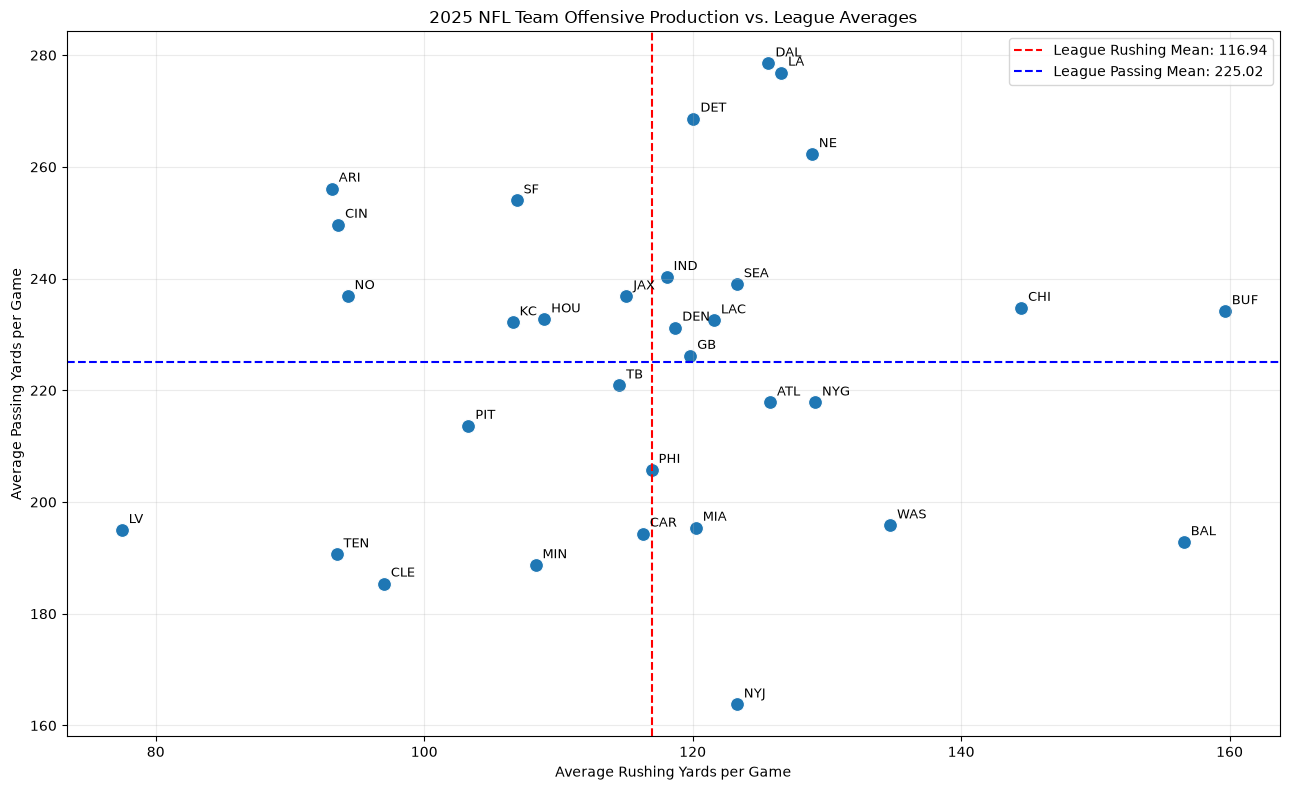

In [9]:
# plot to compare against other teams in this season

plt.figure(figsize=(13, 8))

# Scatterplot of team-season averages
sns.scatterplot(
    data=season_2025,
    x="rushing_mean",
    y="passing_mean",
    s=100
)

# Label each team
for _, row in season_2025.iterrows():
    plt.annotate(
        row["team"],
        (row["rushing_mean"], row["passing_mean"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# League-wide reference lines
plt.axvline(
    league_rushing,
    color="red",
    linestyle="--",
    label=f"League Rushing Mean: {league_rushing:.2f}"
)

plt.axhline(
    league_passing,
    color="blue",
    linestyle="--",
    label=f"League Passing Mean: {league_passing:.2f}"
)

plt.title("2025 NFL Team Offensive Production vs. League Averages")
plt.xlabel("Average Rushing Yards per Game")
plt.ylabel("Average Passing Yards per Game")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()




### Classification of NFL Team Offensive Profiles (2025)

NFL teams were classified into four offensive profiles based on their average rushing and passing yards per game relative to the 2025 league-wide averages.

- **Above Average in Both:** Teams producing above-average rushing and passing yards per game, indicating relatively high production in both categories.
- **Passing-Oriented:** Teams with above-average passing production but below-average rushing production.
- **Rushing-Oriented:** Teams with above-average rushing production but below-average passing production.
- **Below Average in Both:** Teams producing below-average rushing and passing yards per game.

These classifications provide a descriptive framework for comparing offensive production across all 32 NFL teams.

**Note:** The categories reflect relative yardage production rather than offensive efficiency or play-calling tendencies. Further analysis of attempts, scoring, and EPA would be necessary to evaluate offensive effectiveness.

,team,rushing_mean,passing_mean,offensive_profile
801,BUF,159.65,234.18,Above Average in Both
803,CHI,144.47,234.76,Above Average in Both
806,DAL,125.65,278.53,Above Average in Both
807,DEN,118.71,231.24,Above Average in Both
808,DET,120.06,268.65,Above Average in Both
809,GB,119.82,226.18,Above Average in Both
811,IND,118.06,240.29,Above Average in Both
814,LA,126.59,276.88,Above Average in Both
815,LAC,121.59,232.53,Above Average in Both
819,NE,128.88,262.29,Above Average in Both


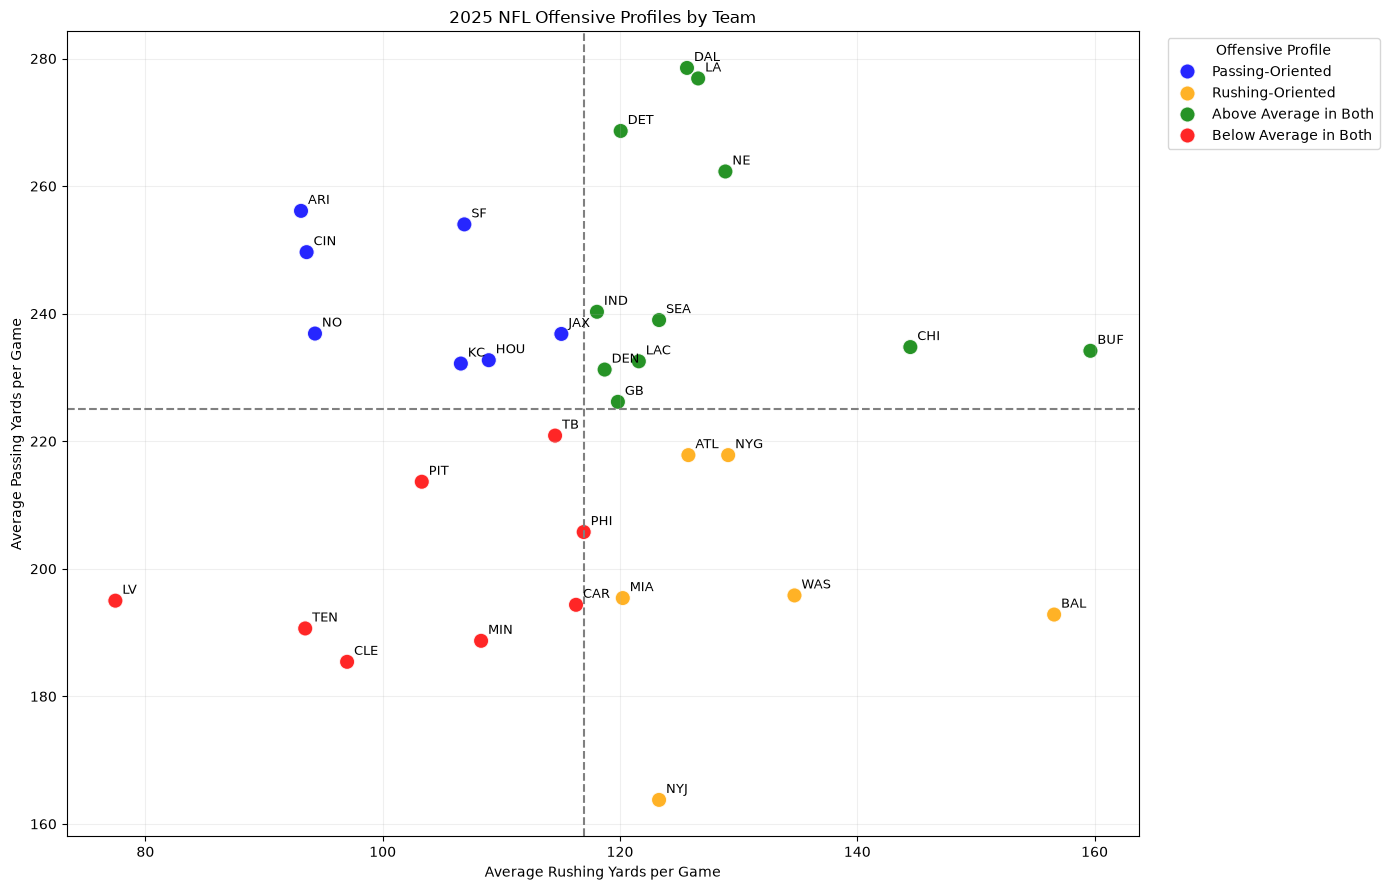

In [10]:
#classifying teams in cateogyrs

conditions = [
    (season_2025["rushing_mean"] >= league_rushing) &
    (season_2025["passing_mean"] >= league_passing),

    (season_2025["rushing_mean"] < league_rushing) &
    (season_2025["passing_mean"] >= league_passing),

    (season_2025["rushing_mean"] >= league_rushing) &
    (season_2025["passing_mean"] < league_passing)
]

categories = [
    "Above Average in Both",
    "Passing-Oriented",
    "Rushing-Oriented",
    
]

season_2025["offensive_profile"] = np.select(
    conditions,
    categories,
    default="Below Average in Both"
)

display(
    season_2025[
        ["team", "rushing_mean", "passing_mean", "offensive_profile"]
    ]
    .sort_values(["offensive_profile", "team"])
    .round(2)
)


# color coded offensive proifle scatterplot
plt.figure(figsize=(14, 9))

sns.scatterplot(
    data=season_2025,
    x="rushing_mean",
    y="passing_mean",
    hue="offensive_profile",
    palette={
        "Above Average in Both": "green",
        "Passing-Oriented": "blue",
        "Rushing-Oriented": "orange",
        "Below Average in Both": "red"
    },
    s=120,
    alpha=0.85
)

# Label each team
for _, row in season_2025.iterrows():
    plt.annotate(
        row["team"],
        (row["rushing_mean"], row["passing_mean"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

# League average reference lines
plt.axvline(
    league_rushing,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

plt.axhline(
    league_passing,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

plt.title("2025 NFL Offensive Profiles by Team")
plt.xlabel("Average Rushing Yards per Game")
plt.ylabel("Average Passing Yards per Game")

plt.legend(
    title="Offensive Profile",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


Historical Team Peformance
(2000-2025)

In [11]:

# Rank teams within each NFL season

team_season["rushing_rank"] = (
    team_season.groupby("season")["rushing_mean"]
    .rank(ascending=False, method="min")
)

team_season["passing_rank"] = (
    team_season.groupby("season")["passing_mean"]
    .rank(ascending=False, method="min")
)

display(
    team_season[
        [
            "season",
            "team",
             "rushing_mean",
            "rushing_rank",
            "rushing_median",
            "rushing_std",
            "passing_mean",
            "passing_rank",
            "passing_median",
            "passing_std"
        ]
    ].round(2)
)


,season,team,rushing_mean,rushing_rank,rushing_median,rushing_std,passing_mean,passing_rank,passing_median,passing_std
0,2000,ARI,79.88,27.0,80.0,36.47,217.38,16.0,212.0,51.21
1,2000,ATL,75.88,28.0,71.5,31.42,197.88,22.0,186.5,48.12
2,2000,BAL,137.44,5.0,126.5,57.60,193.88,23.0,194.0,62.73
3,2000,BUF,123.07,12.0,120.0,43.39,247.60,8.0,253.0,75.26
4,2000,CAR,74.12,29.0,78.5,40.25,240.62,12.0,238.0,60.38
...,...,...,...,...,...,...,...,...,...,...
825,2025,SEA,123.29,10.0,122.0,41.43,239.00,9.0,244.0,63.00
826,2025,SF,106.88,24.0,91.0,45.55,254.00,6.0,279.0,68.97
827,2025,TB,114.53,21.0,104.0,45.64,220.88,19.0,215.0,76.26
828,2025,TEN,93.47,30.0,82.0,38.45,190.65,29.0,194.0,57.85


looking into how league averages playout as the season progresses. 


In [12]:

league_averages = (
    team_season.groupby("season")
    .agg(
        league_rushing_mean=("rushing_mean", "mean"),
        league_passing_mean=("passing_mean", "mean")
    )
    .reset_index()
)

display(league_averages.round(2))


,season,league_rushing_mean,league_passing_mean
0,2000,112.65,222.35
1,2001,113.29,224.83
2,2002,118.23,230.18
3,2003,117.88,213.94
4,2004,116.71,225.28
5,2005,112.48,218.21
6,2006,117.33,219.24
7,2007,110.95,228.21
8,2008,115.90,224.19
9,2009,116.66,232.26


In [13]:

# Weekly league-wide descriptive statistics

weekly_stats = (
    offense.groupby(["season", "week"])
    .agg(
        team_games=("game_id", "count"),
        rushing_mean=("rushing_yards", "mean"),
        rushing_median=("rushing_yards", "median"),
        passing_mean=("passing_yards", "mean"),
        passing_median=("passing_yards", "median")
    )
    .reset_index()
    .sort_values(["season", "week"])
)

display(weekly_stats.head(20).round(2))




,season,week,team_games,rushing_mean,rushing_median,passing_mean,passing_median
0,2000,1,30,114.53,102.0,208.10,193.5
1,2000,2,30,94.30,97.5,249.20,247.5
2,2000,3,26,107.00,107.5,213.38,189.5
3,2000,4,28,102.25,95.0,223.57,212.5
4,2000,5,28,122.82,133.0,232.18,213.5
5,2000,6,26,108.12,104.0,222.73,230.5
6,2000,7,28,120.00,102.0,231.00,223.0
7,2000,8,28,136.07,124.0,226.82,235.5
8,2000,9,28,108.71,108.5,212.46,211.0
9,2000,10,30,109.47,105.0,228.33,231.5


In [14]:
records = []


for season, season_data in offense.groupby("season"):

    season_data = season_data.sort_values("week")

    for week in sorted(season_data["week"].unique()):

        # Include all team-games through the current week
        games_to_date = season_data.loc[
            season_data["week"] <= week
        ]

        records.append({
            "season": season,
            "week": week,
            "cumulative_team_games": len(games_to_date),

            "rushing_cum_mean":
                games_to_date["rushing_yards"].mean(),

            "rushing_cum_median":
                games_to_date["rushing_yards"].median(),

            "passing_cum_mean":
                games_to_date["passing_yards"].mean(),

            "passing_cum_median":
                games_to_date["passing_yards"].median()
        })

cumulative_stats = pd.DataFrame(records)

# Combine weekly and cumulative statistics
league_progress = weekly_stats.merge(
    cumulative_stats,
    on=["season", "week"],
    validate="one_to_one"
)

display(league_progress.round(2))

,season,week,team_games,rushing_mean,rushing_median,passing_mean,passing_median,cumulative_team_games,rushing_cum_mean,rushing_cum_median,passing_cum_mean,passing_cum_median
0,2000,1,30,114.53,102.0,208.10,193.5,30,114.53,102.0,208.10,193.5
1,2000,2,30,94.30,97.5,249.20,247.5,60,104.42,98.0,228.65,224.5
2,2000,3,26,107.00,107.5,213.38,189.5,86,105.20,100.5,224.03,211.5
3,2000,4,28,102.25,95.0,223.57,212.5,114,104.47,98.0,223.92,211.5
4,2000,5,28,122.82,133.0,232.18,213.5,142,108.09,102.0,225.55,211.5
...,...,...,...,...,...,...,...,...,...,...,...,...
442,2025,14,28,126.11,123.0,215.68,212.5,416,116.19,112.5,226.79,221.5
443,2025,15,32,115.31,113.0,236.03,244.0,448,116.12,112.5,227.45,222.5
444,2025,16,32,125.06,128.5,234.28,215.5,480,116.72,113.5,227.90,222.5
445,2025,17,32,124.31,119.0,210.38,202.5,512,117.19,114.0,226.81,222.0


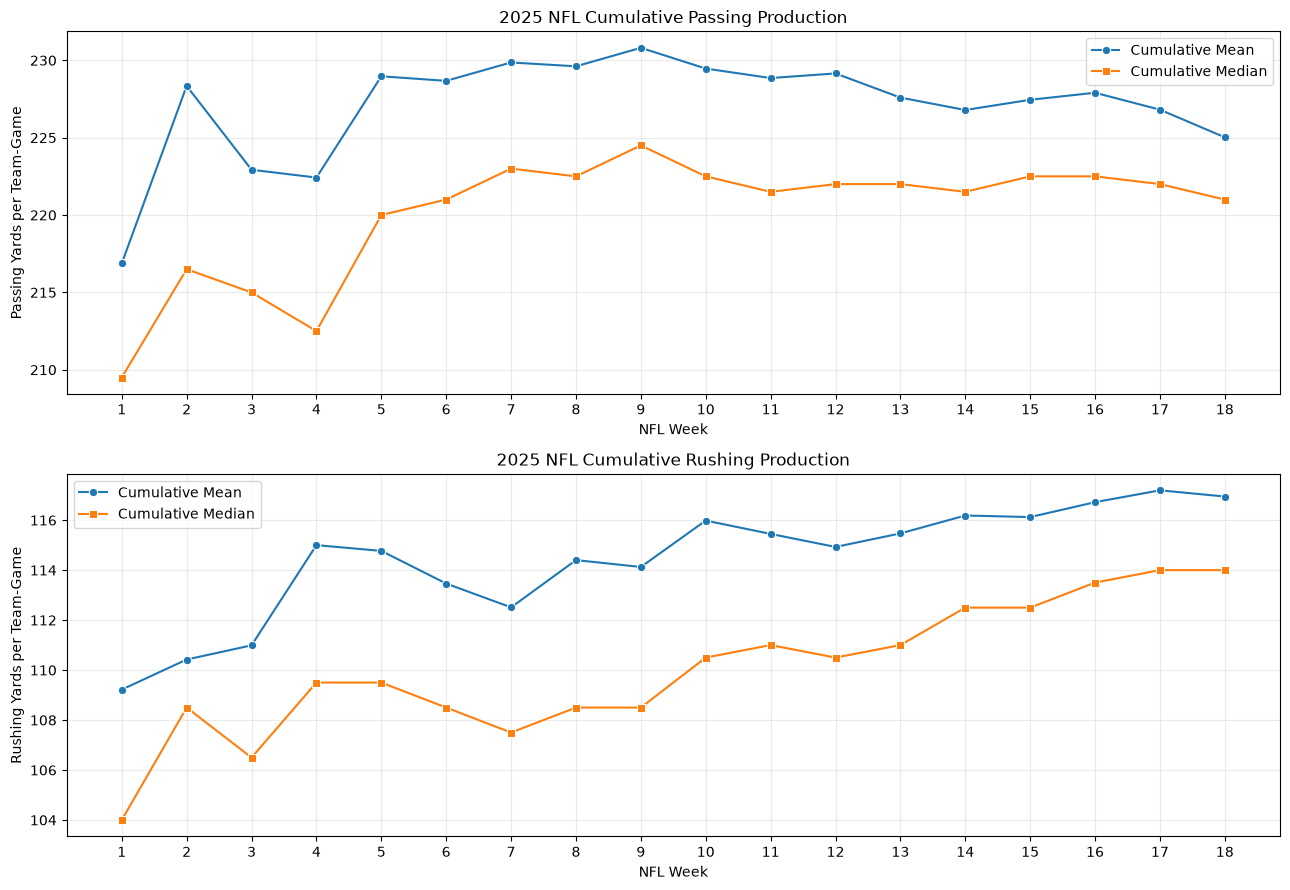

In [15]:
# looking at 2025 just as a rough idea


season_progress = league_progress.loc[
    league_progress["season"] == 2025
]

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Passing
sns.lineplot(
    data=season_progress,
    x="week",
    y="passing_cum_mean",
    marker="o",
    label="Cumulative Mean",
    ax=axes[0]
)

sns.lineplot(
    data=season_progress,
    x="week",
    y="passing_cum_median",
    marker="s",
    label="Cumulative Median",
    ax=axes[0]
)

axes[0].set_title("2025 NFL Cumulative Passing Production")
axes[0].set_ylabel("Passing Yards per Team-Game")

# Rushing
sns.lineplot(
    data=season_progress,
    x="week",
    y="rushing_cum_mean",
    marker="o",
    label="Cumulative Mean",
    ax=axes[1]
)

sns.lineplot(
    data=season_progress,
    x="week",
    y="rushing_cum_median",
    marker="s",
    label="Cumulative Median",
    ax=axes[1]
)

axes[1].set_title("2025 NFL Cumulative Rushing Production")
axes[1].set_ylabel("Rushing Yards per Team-Game")

for ax in axes:
    ax.set_xlabel("NFL Week")
    ax.set_xticks(season_progress["week"])
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()


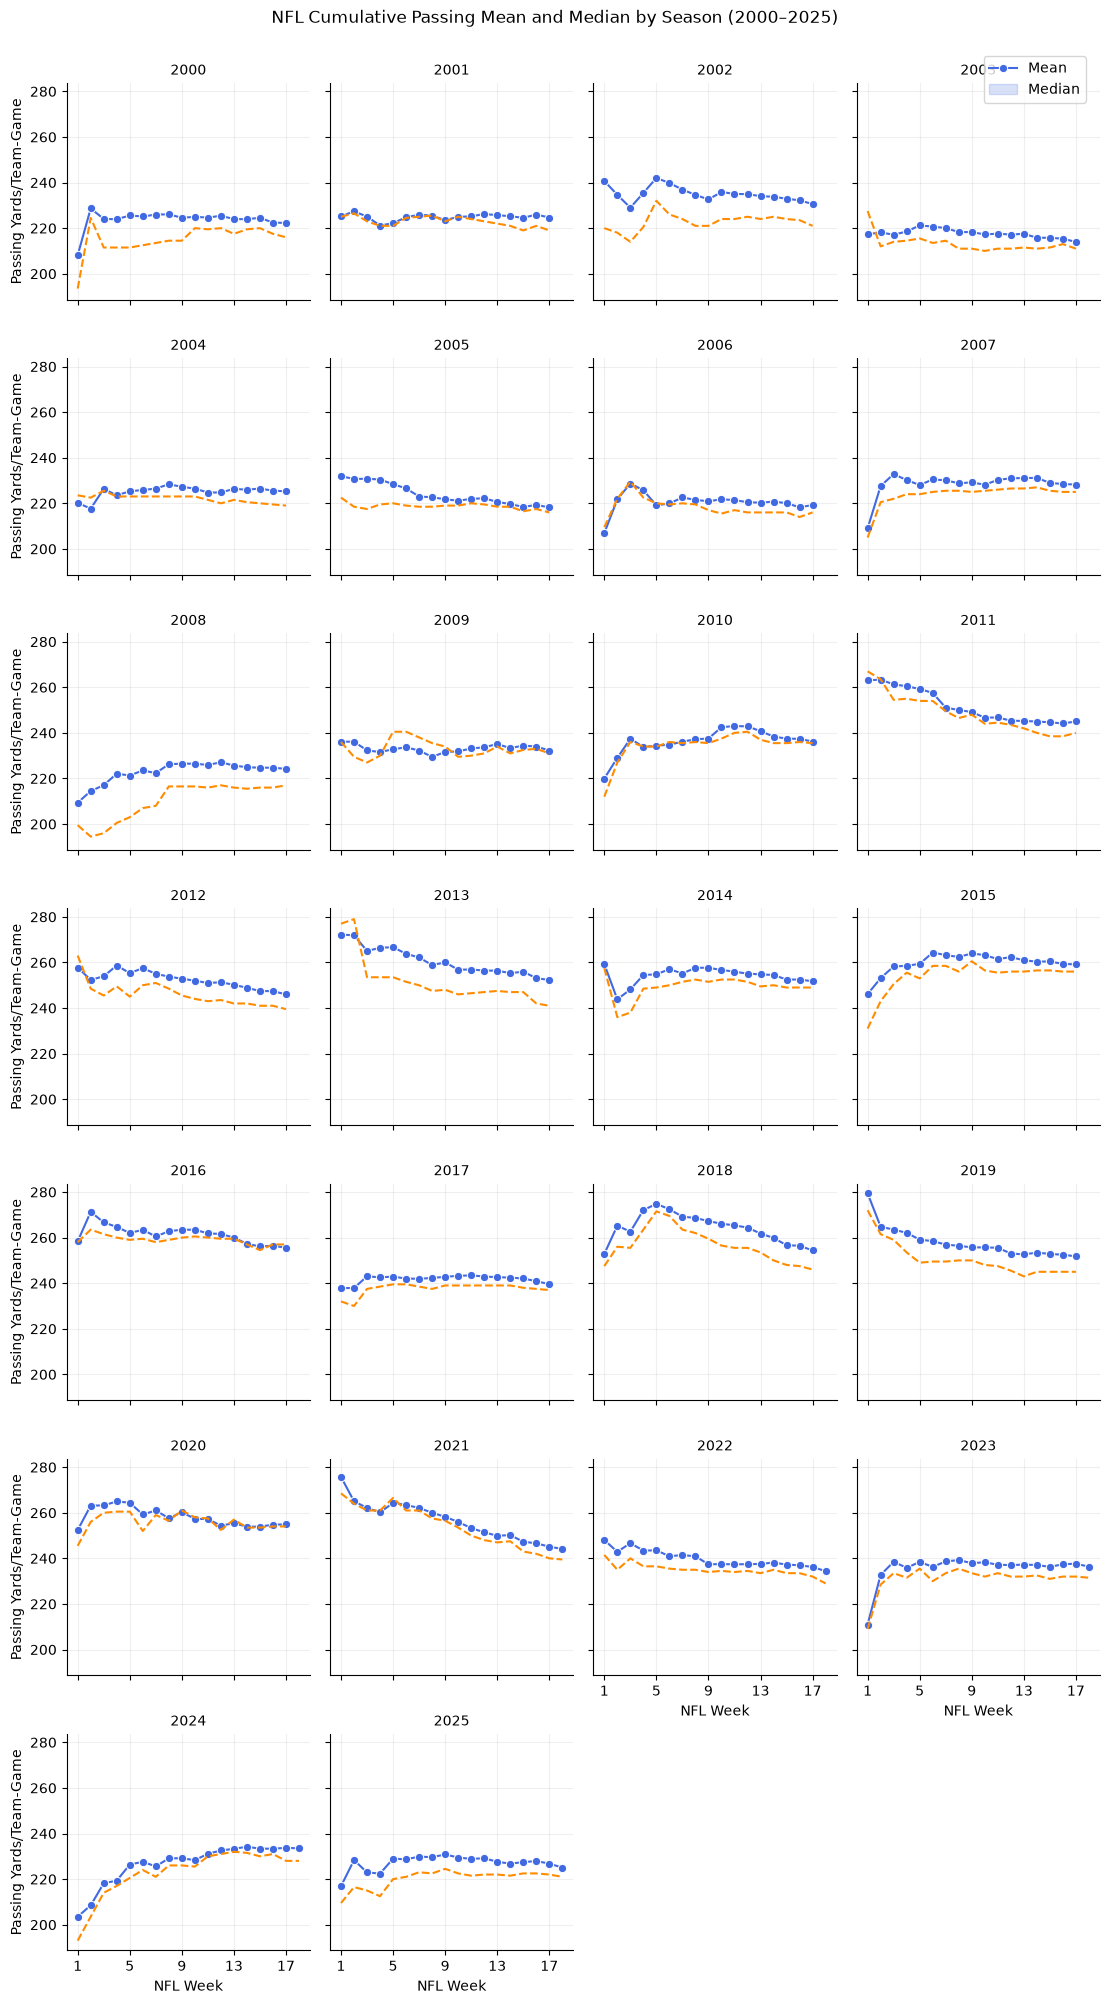

In [17]:
# expanding to 32 teams facet

a = sns.FacetGrid(
    data=league_progress,
    col="season",
    col_wrap=4,
    height=2.8,
    sharex=True,
    sharey=True
)

a.map_dataframe(
    sns.lineplot,
    x="week",
    y="passing_cum_mean",
    color="royalblue",
    marker="o",
    label="Mean"
)

a.map_dataframe(
    sns.lineplot,
    x="week",
    y="passing_cum_median",
    color="darkorange",
    linestyle="--",
    label="Median"
)

a.set_axis_labels("NFL Week", "Passing Yards/Team-Game")
a.set_titles("{col_name}")



for ax in a.axes.flat:
    ax.set_xticks([1,5,9,13,17])
    ax.grid(alpha=0.2)

a.fig.legend(
    ["Mean", "Median"],
    loc="upper right",
    bbox_to_anchor=(0.98, 1.0)
)

a.fig.suptitle(
    "NFL Cumulative Passing Mean and Median by Season (2000–2025)",
    y=1.02
)

plt.show()



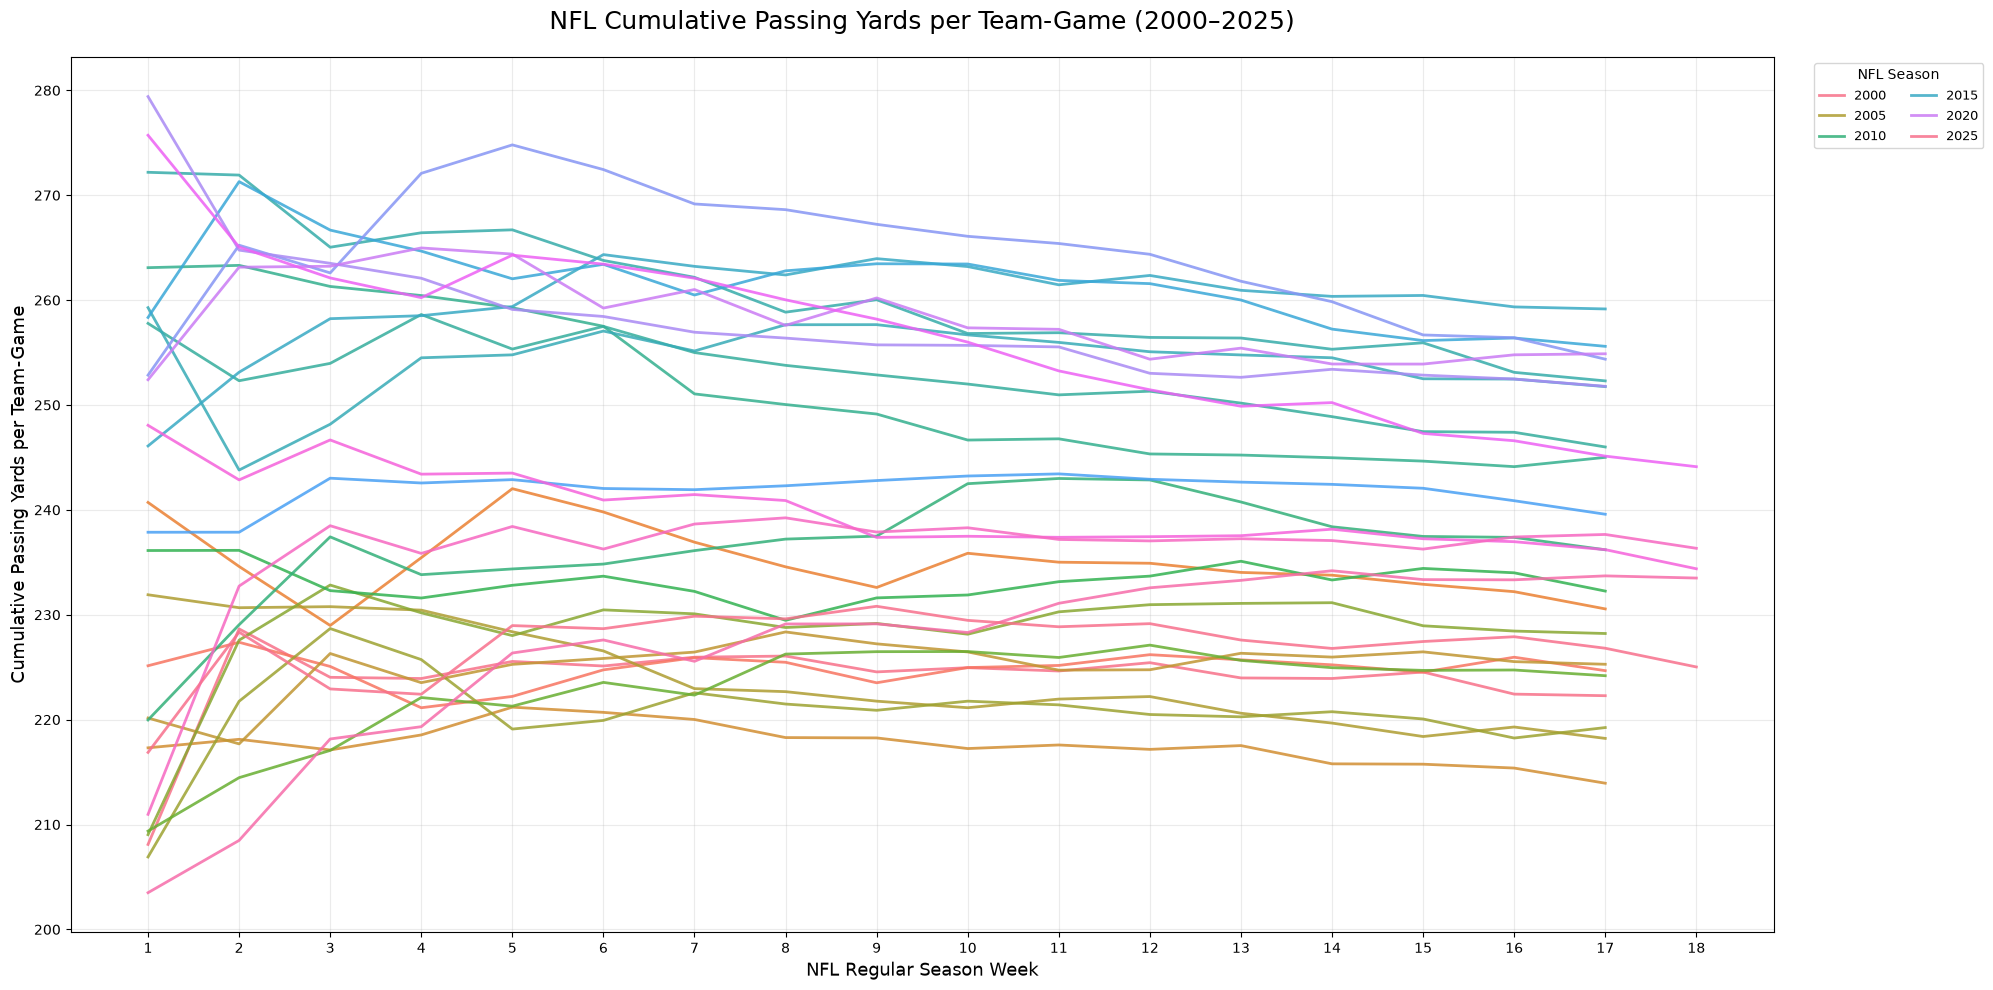

In [21]:

fig, ax = plt.subplots(figsize=(20, 10))

sns.lineplot(
    data=league_progress,
    x="week",
    y="passing_cum_mean",
    hue="season",
    palette="husl",
    units="season",
    estimator=None,
    linewidth=2,
    alpha=0.85,
    ax=ax
)

ax.set_title(
    "NFL Cumulative Passing Yards per Team-Game (2000–2025)",
    fontsize=18,
    pad=20
)

ax.set_xlabel("NFL Regular Season Week", fontsize=13)
ax.set_ylabel("Cumulative Passing Yards per Team-Game", fontsize=13)

ax.set_xticks(range(1, 19))
ax.grid(alpha=0.25)

ax.legend(
    title="NFL Season",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=2,
    fontsize=9
)

plt.tight_layout()
plt.show()


In [18]:

team_season = team_season.merge(
    league_averages,
    on="season",
    how="left",
    validate="many_to_one"
)

# Difference from seasonal league averages
team_season["rushing_diff"] = (
    team_season["rushing_mean"]
    - team_season["league_rushing_mean"]
)

team_season["passing_diff"] = (
    team_season["passing_mean"]
    - team_season["league_passing_mean"]
)

display(
    team_season[
        [
            "season",
            "team",
            "rushing_diff",
            "passing_diff"
        ]
    ].round(2)
)



,season,team,rushing_diff,passing_diff
0,2000,ARI,-32.78,-4.97
1,2000,ATL,-36.78,-24.47
2,2000,BAL,24.78,-28.47
3,2000,BUF,10.41,25.25
4,2000,CAR,-38.53,18.28
...,...,...,...,...
825,2025,SEA,6.35,13.98
826,2025,SF,-10.06,28.98
827,2025,TB,-2.42,-4.14
828,2025,TEN,-23.47,-34.38


In [19]:

print("Top 10 Team-Seasons: Passing Yards per Game")

display(
    team_season.nlargest(
        10, "passing_mean"
    )[
        ["season", "team", "passing_mean", "passing_rank"]
    ].round(2)
)

print("Top 10 Team-Seasons: Rushing Yards per Game")

display(
    team_season.nlargest(
        10, "rushing_mean"
    )[
        ["season", "team", "rushing_mean", "rushing_rank"]
    ].round(2)
)


Top 10 Team-Seasons: Passing Yards per Game


,season,team,passing_mean,passing_rank
423,2013,DEN,348.25,1.0
372,2011,NO,347.75,1.0
15,2000,LA,343.25,1.0
603,2018,TB,334.88,1.0
532,2016,NO,328.62,1.0
371,2011,NE,328.56,2.0
500,2015,NO,325.31,1.0
404,2012,NO,324.19,1.0
600,2018,PIT,323.38,2.0
436,2013,NO,322.62,2.0


Top 10 Team-Seasons: Rushing Yards per Game


,season,team,rushing_mean,rushing_rank
608,2019,BAL,206.00,1.0
640,2020,BAL,191.94,1.0
768,2024,BAL,187.59,1.0
191,2006,ATL,183.69,1.0
56,2001,PIT,179.69,1.0
791,2024,PHI,179.29,2.0
707,2022,CHI,177.29,1.0
473,2014,SEA,172.62,1.0
310,2009,NYJ,172.25,1.0
413,2012,WAS,169.31,1.0


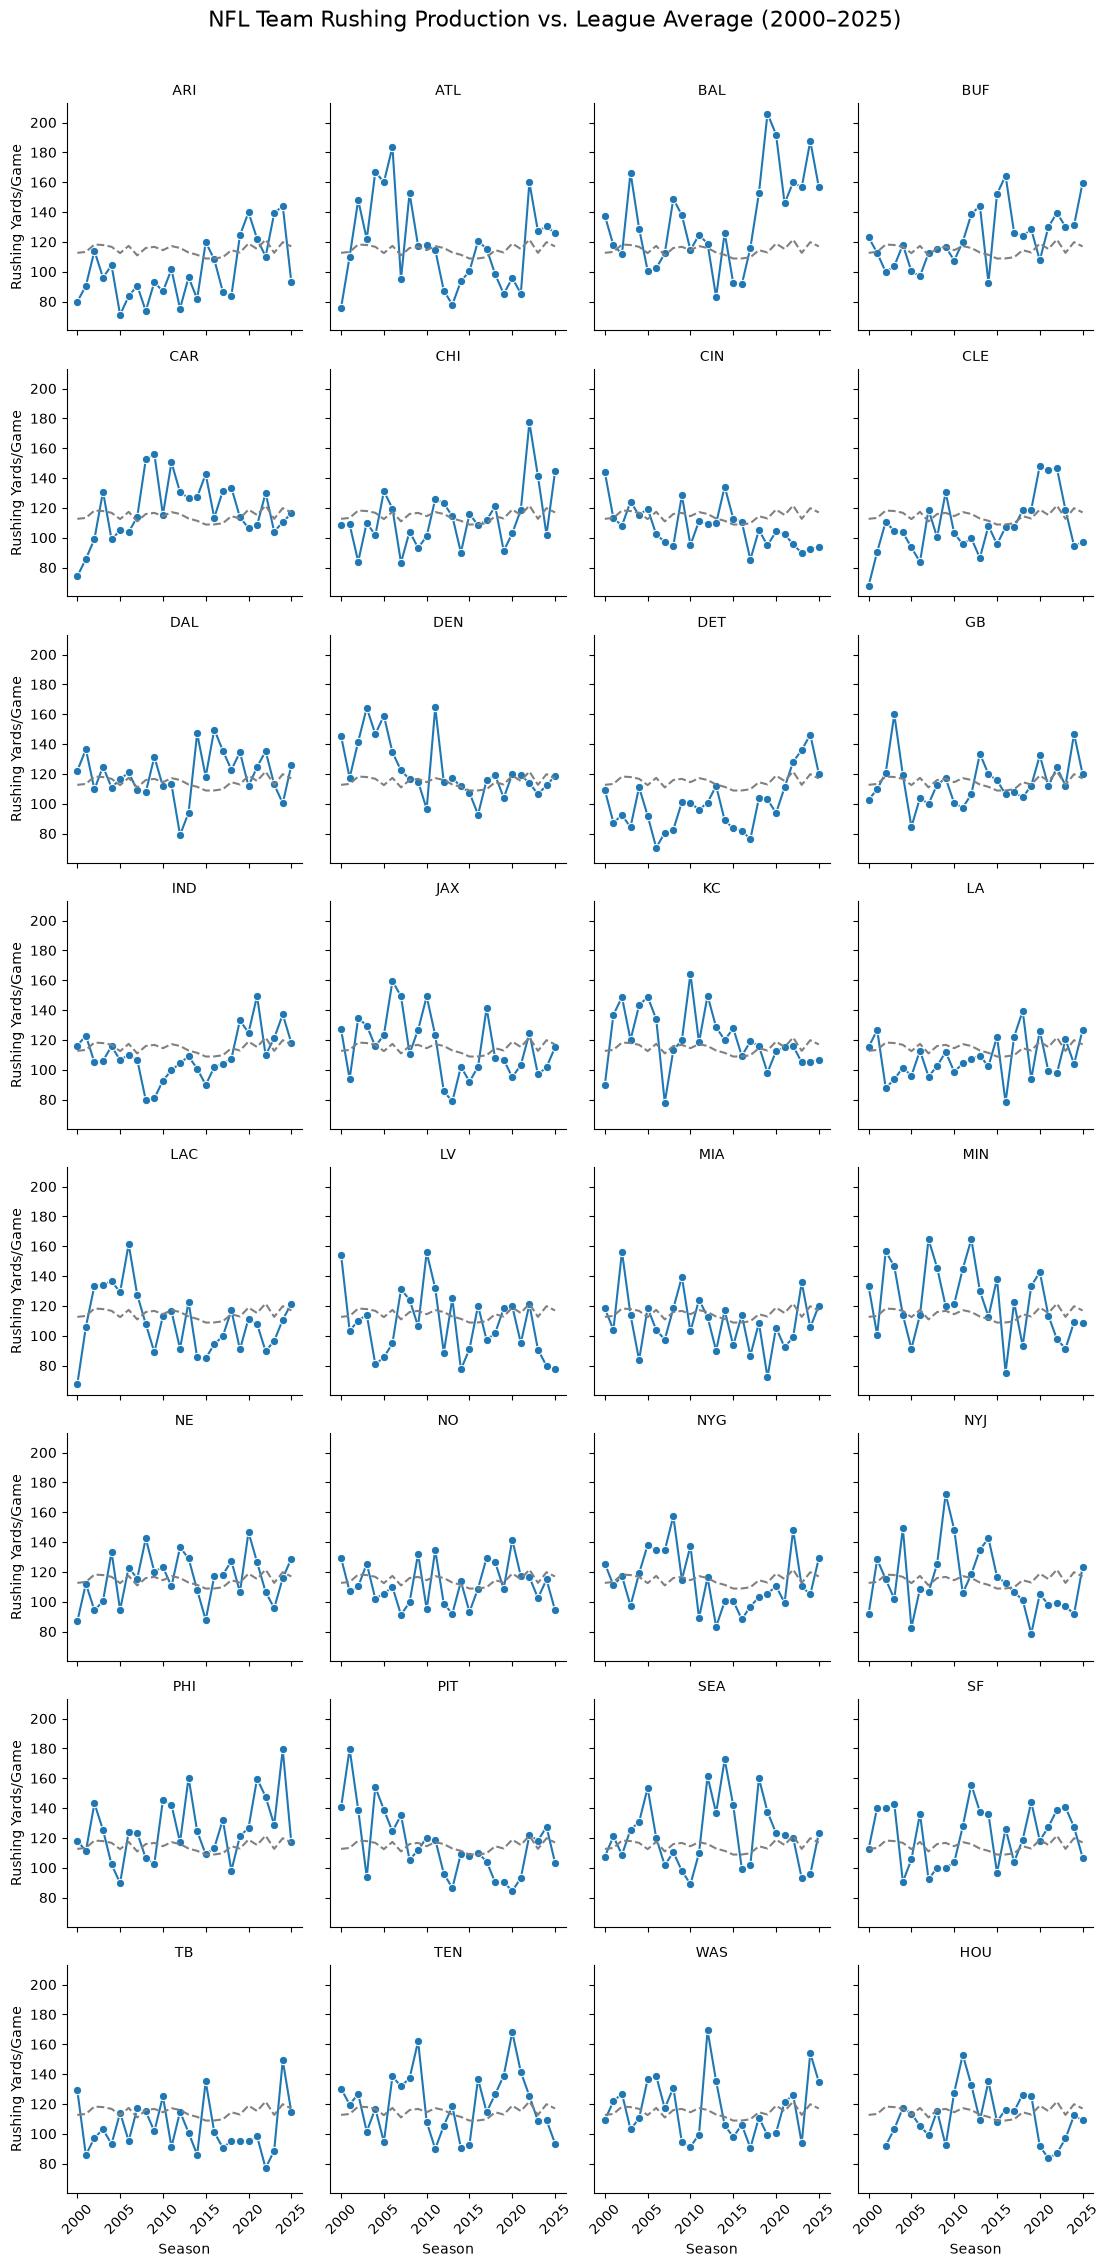

In [22]:

# Historical rushing performance for every NFL team

f = sns.FacetGrid(
    data=team_season,
    col="team",
    col_wrap=4,
    height=2.8,
    sharex=True,
    sharey=True
)

# Team rushing averages
f.map_dataframe(
    sns.lineplot,
    x="season",
    y="rushing_mean",
    marker="o"
)

# Add league averages to every subplot
for ax in f.axes.flat:
    ax.plot(
        league_averages["season"],
        league_averages["league_rushing_mean"],
        linestyle="--",
        color="gray",
        linewidth=1.5
    )

f.set_axis_labels(
    "Season",
    "Rushing Yards/Game"
)

f.set_titles("{col_name}")

f.fig.suptitle(
    "NFL Team Rushing Production vs. League Average (2000–2025)",
    y=1.01,
    fontsize=16
)

for ax in f.axes.flat:
    ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025])
    ax.tick_params(axis="x", labelrotation=45)

f.fig.tight_layout()

plt.show()


In [ ]:

# Historical passing performance for every NFL team

g = sns.FacetGrid(
    data=team_season,
    col="team",
    col_wrap=4,
    height=2.8,
    sharex=True,
    sharey=True
)

g.map_dataframe(
    sns.lineplot,
    x="season",
    y="passing_mean",
    marker="o"
)

# League passing averages
for ax in g.axes.flat:
    ax.plot(
        league_averages["season"],
        league_averages["league_passing_mean"],
        linestyle="--",
        color="gray",
        linewidth=1.5
    )

g.set_axis_labels(
    "Season",
    "Passing Yards/Game"
)

g.set_titles("{col_name}")

g.fig.suptitle(
    "NFL Team Passing Production vs. League Average (2000–2025)",
    y=1.01,
    fontsize=16
)

for ax in g.axes.flat:
    ax.set_xticks([2000, 2005, 2010, 2015, 2020, 2025])
    ax.tick_params(axis="x", labelrotation=45)

g.fig.tight_layout()

plt.show()


In [ ]:
# which team was the most consistent in being above their season above the league average in rushing/passing

historical_consistency = (
    team_season.groupby("team")
    .agg(
        seasons=("season", "nunique"),
        rushing_above_avg=("rushing_diff", lambda x: (x > 0).sum()),
        passing_above_avg=("passing_diff", lambda x: (x > 0).sum())
    )
    .reset_index()
)

historical_consistency["rushing_pct"] = (
    historical_consistency["rushing_above_avg"]
    / historical_consistency["seasons"] * 100
)

historical_consistency["passing_pct"] = (
    historical_consistency["passing_above_avg"]
    / historical_consistency["seasons"] * 100
)

display(
    historical_consistency
    .sort_values("passing_pct", ascending=False)
    .round(2)
)